# Milestone 2: Data Understanding and Pipeline Setup

**Student:** Oisin Hickey | **Module:** Data Handling and Infrastructure for AI  
**GitHub Repository URL:** https://github.com/OisinHick/AI-Hdip  
**Disclaimer:** I used Google Gemini for formatting, spell checking, and table creation.

---

## 1. Project Definition

My project utilizes the Cybersecurity Attack and Defense Dataset (Attack_Dataset.csv) to develop a multi-class classifier 
which will predict the high-level threat category (i.e., Web Application Security, Cloud Security, Malware & Threat, etc.) 
from the text description and some basic metadata of an attack situation. The intended users of this system will be SOC analysts 
and/or incident responders needing to automatically sort incoming security tickets into the appropriate queue. To measure success criteria, 
the pipeline has to include 100% of rows read (i.e., rows_read = good_rows + bad_rows), ensure no duplication or post-incident data "bleed" 
between splits, and outperform the majority class baseline (accuracy = 3.98%).

Changes since Milestone 1 (based upon my EDA):

1. Deduplicate prior to split: As described in Milestone 1, I did split the 14,133 rows of Section 6 first then ran drop_duplicates() 
in Section 10. After reviewing the results of each split, there were 131 duplicate scenarios from the Train set leaking into Dev (47), Test (53), 
and Future Holdout (31). With Milestone 2, I am quarantining duplicate scenarios on (Title, Scenario Description) during validation prior to splitting.

2. Quarantine rather than drop rows with Unnamed: 15: In Milestone 1 I thought that I could simply drop Unnamed: 15 because I believed that it was merely an empty column. 
Upon completing my EDA, I realized that although there were 46 rows which contained values in Unnamed: 15, the values in those rows were a duplicate of the Tools Used field and caused all subsequent columns to shift over one position. There were also 82 rows containing pipe characters (|) in Attack Steps causing the MITRE ID to shift into the Impact column. All of these broken rows are now sent to bad_rows.jsonl.

3. Drop post-incident columns from X: Post-incident columns such as Impact, Detection Method, and Solution are only known after an investigation of an attack has taken place; therefore, using these as inputs for my model would cause temporal/target leakage (Slide 40 Lecture 5). I now only input pre-incident fields into the Column Transformer.

In [1]:
import hashlib
import zipfile
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.model_selection import train_test_split

DELIV_DIR = Path.cwd()
if not (DELIV_DIR / "pipeline.py").exists():
    DELIV_DIR = Path("/home/user/AI-Hdip/Data Handling and Infrastructure/Milestones/Milestone 2/delieverable")

CSV_PATH = DELIV_DIR / "data" / "raw" / "Attack_Dataset.csv"
if not CSV_PATH.exists():
    if (DELIV_DIR / "Attack_Dataset.csv").exists():
        CSV_PATH = DELIV_DIR / "Attack_Dataset.csv"
    elif (DELIV_DIR / "archive.zip").exists():
        extract_dir = Path("/tmp/m2_raw_data")
        extract_dir.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(DELIV_DIR / "archive.zip", "r") as zf:
            zf.extract("Attack_Dataset.csv", path=extract_dir)
        CSV_PATH = extract_dir / "Attack_Dataset.csv"

sha256_hash = hashlib.sha256(CSV_PATH.read_bytes()).hexdigest()
raw_size_mb = CSV_PATH.stat().st_size / (1024 * 1024)
df_raw = pd.read_csv(CSV_PATH)
print(f"Raw dataset shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns ({raw_size_mb:.1f} MB)")
print(f"SHA-256: {sha256_hash}")
print("Columns:", list(df_raw.columns))

# Verify Milestone 1 split-before-dedup leakage across Train / Dev / Test / Future
df_m1 = df_raw.copy()
df_m1.columns = [c.strip() for c in df_m1.columns]
y_m1_raw = df_m1["Category"].fillna("Unknown").astype(str).str.strip()
m1_counts = y_m1_raw.value_counts()
y_m1 = y_m1_raw.apply(lambda c: c if m1_counts[c] >= 10 else "Other Specialised Threats")

pool_m1, fut_m1, y_pool_m1, _ = train_test_split(df_m1, y_m1, test_size=0.10, random_state=42, stratify=y_m1)
train_m1, temp_m1, _, y_temp_m1 = train_test_split(pool_m1, y_pool_m1, test_size=(1/3), random_state=42, stratify=y_pool_m1)
dev_m1, test_m1 = train_test_split(temp_m1, test_size=0.50, random_state=42, stratify=y_temp_m1)

train_keys = set(zip(train_m1["Title"].str.strip(), train_m1["Scenario Description"].str.strip()))
dev_leak = sum(k in train_keys for k in zip(dev_m1["Title"].str.strip(), dev_m1["Scenario Description"].str.strip()))
test_leak = sum(k in train_keys for k in zip(test_m1["Title"].str.strip(), test_m1["Scenario Description"].str.strip()))
fut_leak = sum(k in train_keys for k in zip(fut_m1["Title"].str.strip(), fut_m1["Scenario Description"].str.strip()))
print(f"Milestone 1 duplicate leakage from Train -> Total: {dev_leak + test_leak + fut_leak} (Dev: {dev_leak}, Test: {test_leak}, Future: {fut_leak})")


Raw dataset shape: 14133 rows, 16 columns (17.4 MB)
SHA-256: 130e90c57e33d1791a3f2aad07855dcc80e7d6b0727ecd421376abc2550283d4
Columns: ['ID', 'Title', 'Category', 'Attack Type', 'Scenario Description', 'Tools Used', 'Attack Steps ', 'Target Type', 'Vulnerability', 'MITRE Technique', 'Impact', 'Detection Method', 'Solution', 'Tags', 'Source', 'Unnamed: 15']
Milestone 1 duplicate leakage from Train -> Total: 131 (Dev: 47, Test: 53, Future: 31)


## 2. Data Source, Provenance, Governance and Ethics

The cyber security dataset is available to access via https://www.kaggle.com/datasets/tannubarot/cybersecurity-attack-and-defence-dataset. It was created by Tannu Barot & Savani Dhruv using an MIT license which allows for both academic and commercial use and modification.

Original Dataset Size: Raw file has 14,133 rows with 16 fields (SHA-256: 130e90c57e33d1791a3f2aad07855dcc80e7d6b0727ecd421376abc2550283d4) and is stored locally as read-only (chmod 444).

Limitations Regarding Ethics, Privacy, & Bias: No identifiable information or PII exists within this dataset. The IP address and URL used in each step of an attack are private RFC 1918 lab ranges (i.e., such as 192.168.1.x or localhost). Sampling/Representation Bias: This dataset consists of a collection of educational materials (such as OWASP training resources, MITRE ATT&CK, training labs) that have been developed primarily for educational purposes. As a result, almost all categories of threats include roughly 500 examples. In a real world Security Operations Center (SOC), it can be expected that phishing and web-based exploits would greatly exceed examples of Quantum Cryptography and Satellite Attacks.

---

## 3. Data Description

Each unit of analysis is a single documented cyber attack scenario that makes up each row of this data set. 
Of the 14,133 raw rows in total, there were 393 rows quarantined based on validation rules which includes;
262 duplicated scenarios, 82 rows with shifted pipes (ie. The values in adjacent columns have been swapped);
46 rows had extra comma-separated values that shifted data into the Unnamed: 15 column;
And 3 truncated rows. 
This left 13,740 valid rows to be analyzed.

The table below lists the main columns of this data set and their semantic roles in relation to how they are stored by pandas (slide 9 lecture 4) with missing values counts and an explanation of use.

| Column | Semantic Role | Dtype | Raw Missing | Pipeline Role |
| :--- | :--- | :--- | :--- | :--- |
| `ID` | Record Identifier | `int32` | 0 | Excluded from features (identifier only) |
| `Title` | Short Text | `string` | 0 | Input feature (text) |
| `Category` | Target Label (`y`) | `category` | 0 | Target variable (59 classes after grouping <10 into `Other`) |
| `Attack Type` | Sub-category Label | `string` | 0 | Excluded from `X` (too close to target label) |
| `Scenario Description` | Unstructured Text | `string` | 0 | Input feature (TF-IDF + word/char length) |
| `Tools Used` | Semi-structured List | `string` | 14 (0.10%) | Input feature (`tool_count`; missing imputed as `Unknown`) |
| `Attack Steps` | Procedural Text | `string` | 0 | Input feature (`steps_word_count`) |
| `Target Type` | Nominal Categorical | `category` | 4 (0.03%) | Input feature (`OneHotEncoder`) |
| `Vulnerability` | Text / CVE | `string` | 18 (0.13%) | Kept in cleaned table (imputed as `Unknown`) |
| `MITRE Technique` | Catalog ID (`Txxxx`) | `string` | 24 (0.17%) | Excluded from `X` (curated with label) |
| `Impact` / `Detection` / `Solution` | Post-incident Text | `string` | 3–4 each | Excluded from `X` (post-incident leakage) |
| `Source` | Provenance Category | `category` | 160 (1.13%) | Excluded from `X` (curation source confounder) |
| `Unnamed: 15` | CSV Overflow Column | `string` | 14,087 (99.67%) | Used to catch the 46 shifted rows, then dropped |

---

## 4. Exploratory Data Analysis (EDA)

### 4.1 Missingness (MCAR vs MAR vs MNAR)
Outside of Unnamed: 15, all missing values were below 1.2%, however, they did NOT appear to be Missing Completely At Random (MCAR). The missingness by Category revealed 20 of the 24 missing MITRE Techniques had occurred within Digital Forensics (DFIR) since digital forensic procedures such as using tools like dd or FTK Imager for disk imaging are considered defensive actions rather than attack techniques (MAR). Similarly, there were 13 of the 14 missing Tool Utilization rows that have occurred under Insider Threat & Physical Attacks when no software tool has been utilized (MNAR/structural zero). Therefore, if I drop the rows based on having missing data then I will introduce biased results against both Digital Forensic and Insider Threat. Thus, I will impute these missing values with 'Unknown', and set tool_count = 0.

Columns with missing values in raw dataset:
                  missing_count  missing_pct
Tools Used                   14         0.10
Target Type                   4         0.03
Vulnerability                18         0.13
MITRE Technique              24         0.17
Impact                        3         0.02
Detection Method              4         0.03
Solution                      3         0.02
Tags                          3         0.02
Source                      160         1.13
Unnamed: 15               14087        99.67

Missing MITRE Technique by Category (MAR):
{'DFIR': 20, 'AI Agents & LLM Exploits': 1, 'Malware & Threat': 1, 'Wireless Attacks (Advanced)': 1, 'Virtualization & Container Security → Defensive Evasion & Persistence → 🛡️ Evading Container Security Tools': 1}

Missing Tools Used by Category (MNAR / structural zero):
{'Insider Threat': 9, 'Physical / Hardware Attacks': 4, 'Browser Security → Cookie Theft & Session Hijacking': 1}

Rows where Unnamed: 15 is not

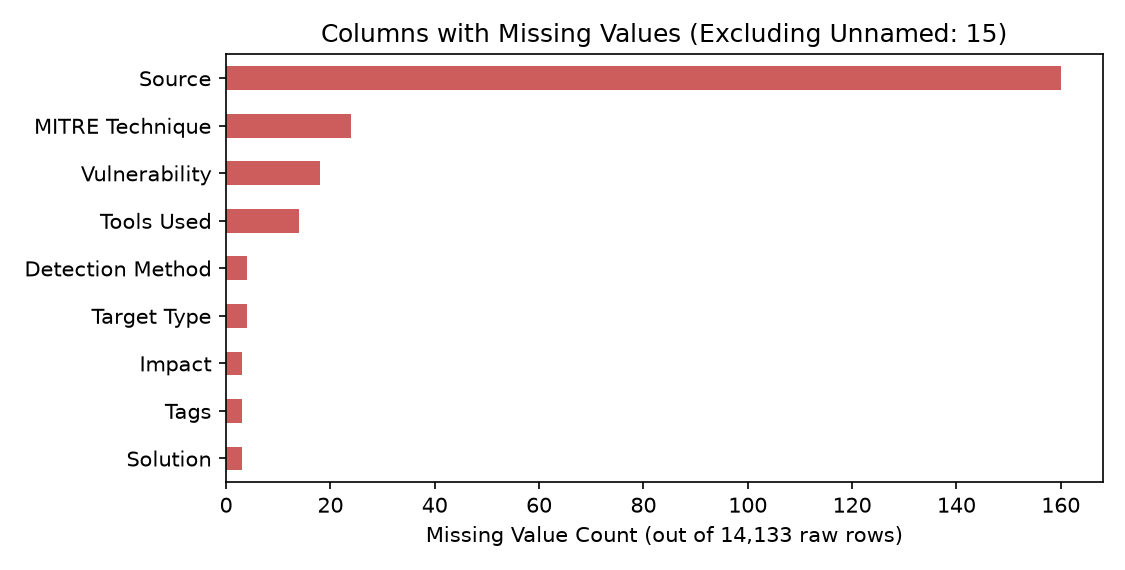

In [2]:
# Check raw missing values per column (out of 14,133 rows)
df_raw.columns = [c.strip() for c in df_raw.columns]
missing_counts = df_raw.isna().sum()
missing_pct = (df_raw.isna().mean() * 100).round(2)
miss_table = pd.DataFrame({"missing_count": missing_counts, "missing_pct": missing_pct})
print("Columns with missing values in raw dataset:")
print(miss_table[miss_table["missing_count"] > 0])

# MAR / MNAR breakdown by Category
print("\nMissing MITRE Technique by Category (MAR):")
print(df_raw[df_raw["MITRE Technique"].isna()]["Category"].value_counts().to_dict())

print("\nMissing Tools Used by Category (MNAR / structural zero):")
print(df_raw[df_raw["Tools Used"].isna()]["Category"].value_counts().to_dict())

# Check rows where Unnamed: 15 is not null
u15_rows = df_raw[df_raw["Unnamed: 15"].notna()]
print(f"\nRows where Unnamed: 15 is not null: {len(u15_rows)} (Categories: {u15_rows['Category'].value_counts().to_dict()})")


### 4.2 Target Variable and Class Balance
The majority of the 59 target categories can be grouped together by the main categories containing approximately 450-547 rows for most of them (after deduplication) and largest being Physical/Hardware Attacks at 547/13,740 or 3.98% as the majoritry baseline. The remaining 4 rare automotive subcategories that contain less than 10 rows each will all be placed in "Other Specialized Threats" since they do not fit within their respective main categories. These categories also include a small number of subcategories that were created using an arrow to represent how one category is a subcategory of another (e.g., Browser Security -> XSS) which resulted in a smaller amount of data entries ranging from 10-60 per subcategory.

Pipeline finished -> rows_read: 14133, good_rows: 13740, bad_rows: 393
Total valid rows: 13740 across 59 target classes (28 main categories + 31 arrow subcategories)
Largest class (majority baseline): Physical / Hardware Attacks = 547/13740 (3.98%)

Top 10 categories (after deduplication and quarantine):
Target_Category
Physical / Hardware Attacks                    547
Quantum Cryptography & Post-Quantum Threats    542
Malware & Threat                               526
Wireless Attacks (Advanced)                    518
Insider Threat                                 512
Blue Team                                      502
Cryptography Attacks                           501
Email & Messaging Protocol Exploits            500
Blockchain / Web3                              499
Mobile Security                                498
Name: count, dtype: int64

Rare categories with < 10 records grouped into 'Other Specialised Threats':
Category
Automotive / Cyber-Physical Systems → ECU Reverse Engine

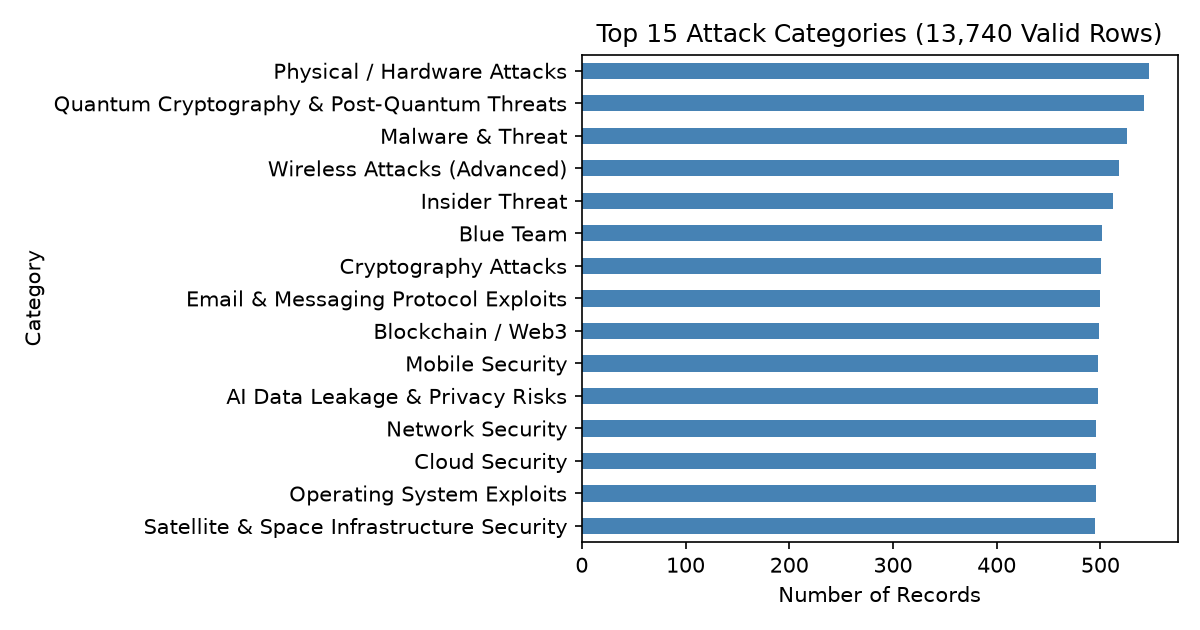

In [3]:
import sys
if str(DELIV_DIR) not in sys.path:
    sys.path.insert(0, str(DELIV_DIR))
from pipeline import run_pipeline

out_dir = Path("/tmp/m2_pipeline_out")
counters = run_pipeline(CSV_PATH, out_dir)
df_clean = pd.read_parquet(out_dir / "attack_features_v2.parquet")

cat_counts_valid = df_clean["Target_Category"].astype(str).value_counts()
arrow_cats = [c for c in cat_counts_valid.index if "→" in c or "->" in c]
print(f"Total valid rows: {len(df_clean)} across {len(cat_counts_valid)} target classes ({len(cat_counts_valid) - len(arrow_cats)} main categories + {len(arrow_cats)} arrow subcategories)")
print(f"Largest class (majority baseline): {cat_counts_valid.index[0]} = {cat_counts_valid.iloc[0]}/{len(df_clean)} ({cat_counts_valid.iloc[0]/len(df_clean):.2%})")
print("\nTop 10 categories (after deduplication and quarantine):")
print(cat_counts_valid.head(10))

raw_cat_clean = df_raw["Category"].astype(str).str.strip().replace({"Network security": "Network Security"})
print("\nRare categories with < 10 records grouped into 'Other Specialised Threats':")
print(raw_cat_clean.value_counts()[raw_cat_clean.value_counts() < 10])


### 4.3 Numerical Summaries (Sensitive vs Resistant), Skewness, and ECDFs
Following Lecture 4 Slide 11 and Lecture 5 Slide 16, the table below compares mean and standard deviation (sensitive to outliers) with median and IQR (resistant) on the 13,740 valid rows.

| Feature | Mean | Std | Median | IQR | 1.5xIQR Fence | Outliers > Fence | Raw Skew | `log1p` Skew |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| `scenario_len` (chars) | 128.60 | 91.82 | 104.0 | 64.0 | 240.0 | 880 (6.4%) | 3.49 | 1.14 |
| `scenario_word_count` | 19.19 | 13.99 | 16.0 | 9.0 | 34.5 | 934 (6.8%) | 3.53 | 1.17 |
| `steps_word_count` | 106.81 | 68.78 | 84.0 | 80.0 | 259.0 | 507 (3.7%) | 2.09 | 0.31 |
| `tool_count` | 3.02 | 1.33 | 3.0 | 1.0 | 4.5 | 1,287 (9.4%) | 2.40 | 0.20 |

As demonstrated by both the histogram and ECDF plots shown below, the data for the variable, scenario_word_count has a significant amount of right-skew bias (mean=19.2; Median=16.0; Skewness = 3.53). Upon reviewing the first 934 rows where the number of words was greater than 1.5 times the Interquartile Range (IQR) (i.e., 34.5), I noticed that virtually all the observations came from two categories: AI/ML Security (Median=63 words) and AI Agents & LLM Exploits (Median=41 words). If I had removed these data points, it would have been necessary to delete approximately 90% or more of the data from the AI/ML Security category. To prevent this, I retained those records but applied the transformation log1p(x) to reduce the skewness from 3.53 to 1.17 (steps_word_count reduced from 2.09 to .31 as well). The Chi-Square Test for Association between Category and Source resulted in a probability value less than 1e-100 (Cramér’s V=.85); therefore, I am able to conclude that there is an association between Source and how data collections were carried out.

### Traceability Summary (EDA Finding -> Pipeline Decision -> Limitation)

| EDA Finding | Pipeline Decision | Limitation |
| :--- | :--- | :--- |
| 131 shifted / truncated rows (`Unnamed: 15` & pipe `\|` shifts) | Quarantine to `bad_rows.jsonl` in `validate_row()` | `SCADA/ICS` loses 49 corrupted rows (452 -> 403) |
| 262 duplicate `(Title, Scenario Description)` rows | Deduplicate in `validate_row()` before train/test split | Near-duplicates with slightly reworded text may remain |
| Missing values in `DFIR` (MITRE) and `Insider Threat` (Tools) | Impute `'Unknown'` / `'Unmapped'` and `tool_count=0` | Imputed token is a rough placeholder |
| Heavy right skew on word/tool counts (AI categories > `1.5xIQR`) | Keep extreme rows; apply `FunctionTransformer(np.log1p)` | AI scenarios are still longer on average than other classes |

            Feature   Mean   Std  Median  IQR  1.5xIQR Fence Outliers > Fence  Raw Skew  log1p Skew
       scenario_len 128.60 91.82   104.0 64.0          240.0       880 (6.4%)      3.49        1.14
scenario_word_count  19.19 13.99    16.0  9.0           34.5       934 (6.8%)      3.53        1.17
   steps_word_count 106.81 68.78    84.0 80.0          259.0       507 (3.7%)      2.09        0.31
         tool_count   3.02  1.33     3.0  1.0            4.5      1287 (9.4%)      2.40        0.20

AI/ML Security: median=63 words, 92.5% of rows > 1.5xIQR fence (34.5)

AI Agents & LLM Exploits: median=41 words, 56.4% of rows > 1.5xIQR fence (34.5)

Chi-square test (Category vs Source): chi2=575290.2, p=0.00e+00 (< 1e-100), Cramer's V=0.85
SCADA/ICS rows: 452 raw -> 403 valid (lost 49 corrupted rows)


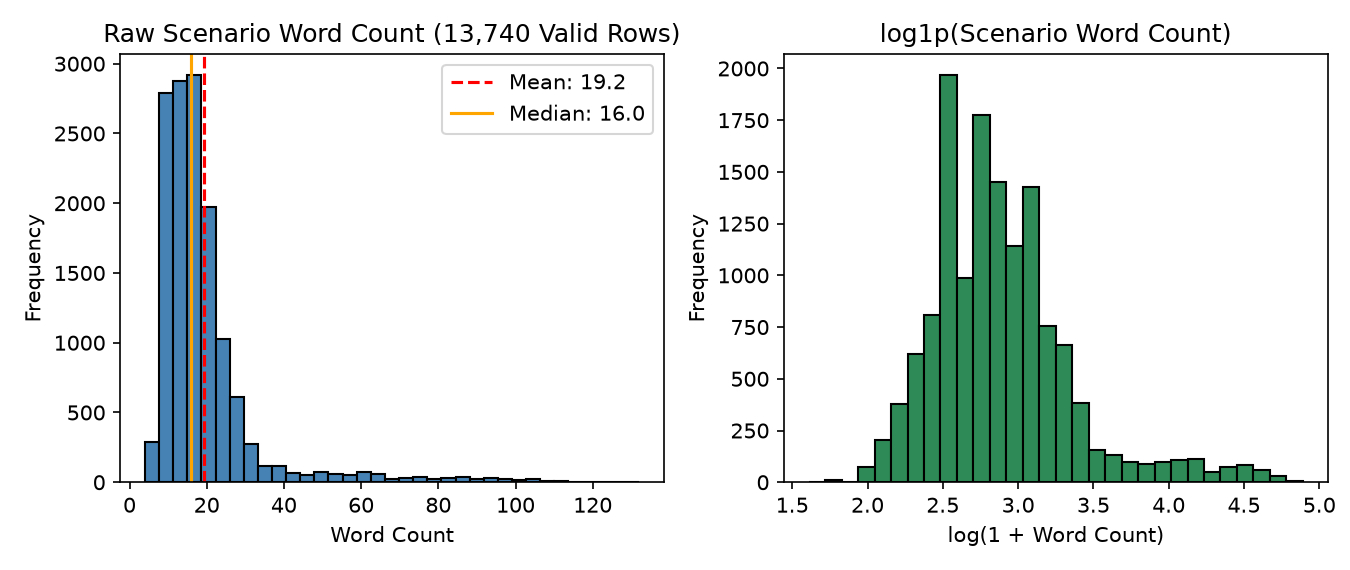

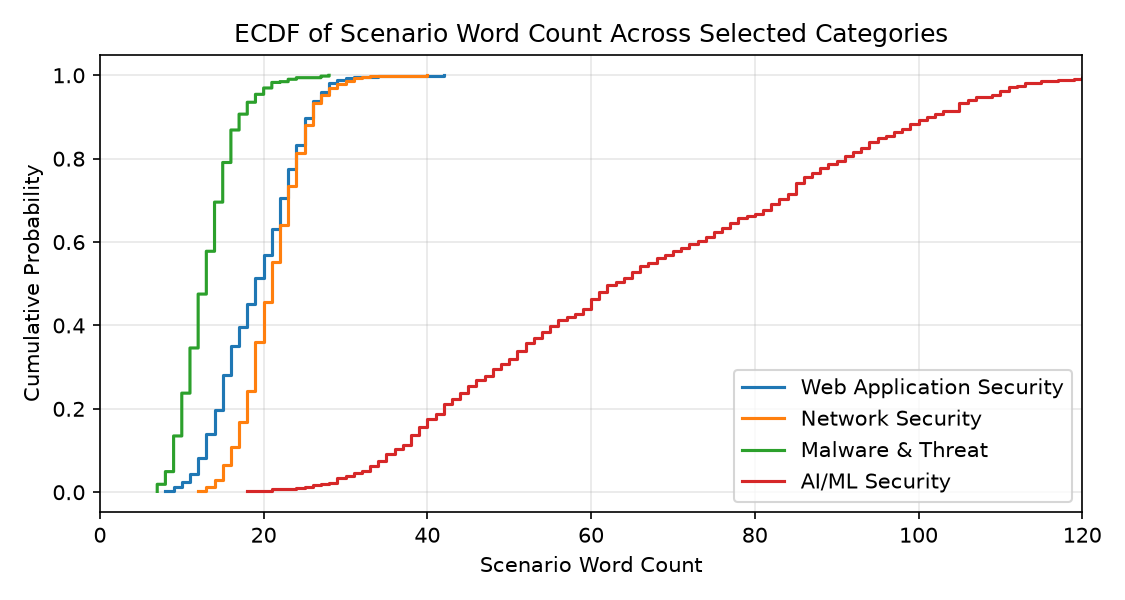

In [4]:
summary_rows = []
for col in ["scenario_len", "scenario_word_count", "steps_word_count", "tool_count"]:
    s = df_clean[col].astype(float)
    q25, q75 = s.quantile(0.25), s.quantile(0.75)
    iqr = q75 - q25
    fence = q75 + 1.5 * iqr
    outliers = int((s > fence).sum())
    pct = outliers / len(s) * 100
    summary_rows.append({
        "Feature": col,
        "Mean": round(s.mean(), 2),
        "Std": round(s.std(), 2),
        "Median": round(s.median(), 1),
        "IQR": round(iqr, 1),
        "1.5xIQR Fence": round(fence, 1),
        "Outliers > Fence": f"{outliers} ({pct:.1f}%)",
        "Raw Skew": round(float(stats.skew(s)), 2),
        "log1p Skew": round(float(stats.skew(np.log1p(s))), 2),
    })

print(pd.DataFrame(summary_rows).to_string(index=False))

# Check AI category medians and proportion > 34.5 word fence
for ai_cat in ["AI/ML Security", "AI Agents & LLM Exploits"]:
    sub = df_clean[df_clean["Target_Category"].astype(str) == ai_cat]["scenario_word_count"]
    pct_above = (sub > 34.5).mean() * 100
    print(f"\n{ai_cat}: median={sub.median():.0f} words, {pct_above:.1f}% of rows > 1.5xIQR fence (34.5)")

# Chi-square test & Cramer's V between Category and Source
ct = pd.crosstab(df_clean["Target_Category"].astype(str), df_clean["Source"].astype(str))
chi2, p_val, dof, _ = stats.chi2_contingency(ct)
n = ct.to_numpy().sum()
r, k = ct.shape
cramers_v = np.sqrt(chi2 / (n * min(r - 1, k - 1)))
print(f"\nChi-square test (Category vs Source): chi2={chi2:.1f}, p={p_val:.2e} (< 1e-100), Cramer's V={cramers_v:.2f}")

# SCADA/ICS row count before vs after quarantine
scada_raw = (raw_cat_clean == "SCADA/ICS").sum()
scada_clean = (df_clean["Target_Category"].astype(str) == "SCADA/ICS").sum()
print(f"SCADA/ICS rows: {scada_raw} raw -> {scada_clean} valid (lost {scada_raw - scada_clean} corrupted rows)")


---

## 5. Pipeline Architecture and Storage Design

The pipeline in pipeline.py is comprised of five major stages, including those referenced in Lecture 6 and Lab 6:

1. Ingest: Reads the original, read-only csv files Attack_Dataset.csv (which contains 14,133 rows), and cleans all additional white-space off the column header names.

2. Validate & Quarantine (validate_row()): Validates each row against the Data Contract for the project. All non-valid (or broken/duplicate) rows (i.e., 393 total rows that include 46 Unnamed: 15 overflow rows; 82 pipe-shifted rows; three truncated rows; and 262 duplicate scenarios) will be written to outputs/bad_rows.jsonl along with an associated reason tag. The remaining 13,740 valid rows continue through the pipeline.

3. Clean & Engineer Features (transform_good_row()): Corrects spelling errors for Category Names; aggregates rare Categories (< 10 total rows) into Other Specialized Threats; replaces missing Categorical Values with 'Unknown'; and computes scenario_len, scenario_word_count, steps_word_count, and tool_count. A copy of the clean Dataset is then saved to both outputs/attack_features_v2.parquet and outputs/category_summary.csv.

4. Stratified Split: Randomly splits the 13,740 valid rows into Training = 60%, Development = 15%, Testing = 15%, and a Future Holdout set of 10% (total of 1,374 rows) using a random state of 42.

5. Preprocess (build_preprocessor()): Builds a ColumnTransformer by first fitting it to only the Training subset of data (for the purpose of avoiding data leak); transforms the same features on the Development subset; and does likewise on the Testing subset.

Storage Design: The original data remains as CSV files originally downloaded from Kaggle (and verified by SHA-256 hash). The Cleaned Data is stored in Apache Parquet format attack_features_v2.parquet using pyarrow and Snappy compression - resulting in a reduction of size from approximately 17.4 MB down to roughly ~7.3 MB and maintaining all column dtypes. The bad_rows.jsonl file stores all non-cleaned rows so that each failed row may have a recorded reason. Both running pipeline.py and running pytest is accomplished automatically via CLI. Downloading the original CSV file from Kaggle and reviewing all EDA plots within the provided Jupyter Notebook are manually completed tasks.

---

## 6. Pipeline implementation and validating evidence

Implementation of the pipeline has been made in pipeline.py file. The implementation was validated through five unit tests included in the test_pipeline.py file (valid rows, missing fields, wrong id’s, unnamed: 15 shift and duplicate scenario.) running pytest and pipeline.py on the full dataset returns:

```text
$pytest -v test_pipeline.py
5 passed in 0.89 s

$python pipeline.py --input data/raw/attack_dataset.csv --out outputs
Finished pipeline -> rows_read: 14133, good_rows: 13740, bad_rows: 393
Bad_rows breakdown: duplicate_scenario=262, pipe delimiter = 82, unnamed_15 = 46, truncated_row=3
Sizes of split: train_rows=8244, dev_rows=2061, test_rows=2061, future_rows=1374
```

The accounting check also works since the data de-duplication occurs prior to splitting into train/test/dev/future sets therefore there are no duplicated scenarios present among test and train /dev/future.

In [5]:
import subprocess

# 1. Run unit tests in test_pipeline.py
res = subprocess.run(
    [sys.executable, "-m", "pytest", "-v", str(DELIV_DIR / "test_pipeline.py")],
    capture_output=True,
    text=True,
)
for line in res.stdout.splitlines():
    if "::" in line or "passed" in line:
        print(line)

# 2. Verify pipeline counters and storage size reduction (CSV vs Parquet)
parquet_path = out_dir / "attack_features_v2.parquet"
parquet_size_mb = parquet_path.stat().st_size / (1024 * 1024)
print(f"\nPipeline counters: {counters}")
print(f"Accounting check: rows_read ({counters['rows_read']}) == good_rows ({counters['good_rows']}) + bad_rows ({counters['bad_rows']})")
print(f"Storage reduction: Raw CSV = {raw_size_mb:.2f} MB (~17.4 MB) -> Cleaned Parquet = {parquet_size_mb:.2f} MB (~7.3 MB)")


Data Handling and Infrastructure/Milestones/Milestone 2/delieverable/test_pipeline.py::test_valid_row_passes PASSED [ 20%]
Data Handling and Infrastructure/Milestones/Milestone 2/delieverable/test_pipeline.py::test_missing_required_field_quarantined PASSED [ 40%]
Data Handling and Infrastructure/Milestones/Milestone 2/delieverable/test_pipeline.py::test_bad_id_quarantined PASSED [ 60%]
Data Handling and Infrastructure/Milestones/Milestone 2/delieverable/test_pipeline.py::test_shifted_unnamed15_quarantined PASSED [ 80%]
Data Handling and Infrastructure/Milestones/Milestone 2/delieverable/test_pipeline.py::test_duplicate_row_quarantined PASSED [100%]
============================== 5 passed in 1.27s ===============================

Pipeline counters: {'rows_read': 14133, 'good_rows': 13740, 'bad_rows': 393, 'truncated_row': 3, 'column_shift:pipe_delimiter': 82, 'duplicate_scenario': 262, 'column_shift:Unnamed_15': 46, 'train_rows': 8244, 'dev_rows': 2061, 'test_rows': 2061, 'future_rows':

---

## 7. Next-step plan (milestone 3)

Baseline model results:
In milestonetwo.ipynb, i compared a majority class baseline (DummyClassifier) to a leak-free LogisticRegression pipeline (log1p + StandardScaler on lengths/tool_count, OneHotEncoder on Target Type and TfidfVectorizer on Scenario Description) trained on the train set only:

| Model | Accuracy on dev set | Test accuracy | Macro-F1 on test set |
| :--- | :--- | :--- | :--- |
| Majority class baseline (DummyClassifier) | 3.98 % | 3.98 % | 0.13 % |
| LogisticRegression (leak-free pipeline) | 71.47 % | 70.94 % | 42.08 % |

Plan and limitation for milestone 3: although the accuracy of approximately 71% is achieved across the 59 classes, the Macro-F1 value is lower (approximately 42%) because the 31 smaller subcategories of arrows (e.g., 'browser security -> xss', which has 24 training rows) get misclassified as larger parent categories. To achieve an improvement at milestone three, I will: 

1. Add the Attack Steps and tools used text to the TF-idf vectorizer together with Scenario Description.

2. Compare LinearSVC, Complement Naive Bayes and use class_weight='balanced' to improve precision on the smaller subcategories.

3. Perform evaluation using stratified 5-Fold Cross-Validation and confusion matrices.

Tools used: all of these were created with Standard Python libraries (pandas, scikit-learn, scipy, matplotlib) and AI coding assistant to assist in formatting the code/script/report; all results/data were manually confirmed by executing pipeline.py and pytest on the entire dataset.

In [6]:
from pipeline import build_preprocessor
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import Pipeline

# Stratified split (60% Train, 15% Dev, 15% Test, 10% Future Holdout, random_state=42)
df_pool, df_future = train_test_split(df_clean, test_size=0.10, stratify=df_clean["Target_Category"], random_state=42)
df_train, df_temp = train_test_split(df_pool, test_size=(1/3), stratify=df_pool["Target_Category"], random_state=42)
df_dev, df_test = train_test_split(df_temp, test_size=0.50, stratify=df_temp["Target_Category"], random_state=42)

# Verify zero duplicate scenarios leaked between Train and Dev/Test/Future after pre-split deduplication
clean_train_keys = set(zip(df_train["Title"], df_train["Scenario Description"]))
clean_leak = sum(
    k in clean_train_keys
    for split_df in [df_dev, df_test, df_future]
    for k in zip(split_df["Title"], split_df["Scenario Description"])
)
print(f"Split sizes: Train={len(df_train)}, Dev={len(df_dev)}, Test={len(df_test)}, Future={len(df_future)}")
print(f"Duplicate scenarios leaked across splits after pre-split quarantine: {clean_leak}")

y_train, y_dev, y_test = df_train["Target_Category"], df_dev["Target_Category"], df_test["Target_Category"]

# 1. Majority class baseline (DummyClassifier)
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(df_train, y_train)
pred_dummy_dev = dummy.predict(df_dev)
pred_dummy_test = dummy.predict(df_test)
print(
    f"\nMajority class baseline (DummyClassifier) -> "
    f"Dev Acc: {accuracy_score(y_dev, pred_dummy_dev):.2%}, "
    f"Test Acc: {accuracy_score(y_test, pred_dummy_test):.2%}, "
    f"Test Macro-F1: {f1_score(y_test, pred_dummy_test, average='macro'):.2%}"
)

# 2. Leak-free LogisticRegression pipeline (fit on Train only)
clf = Pipeline([
    ("prep", build_preprocessor()),
    ("lr", LogisticRegression(max_iter=1000, random_state=42)),
])
clf.fit(df_train, y_train)
pred_lr_dev = clf.predict(df_dev)
pred_lr_test = clf.predict(df_test)
print(
    f"LogisticRegression (leak-free pipeline)   -> "
    f"Dev Acc: {accuracy_score(y_dev, pred_lr_dev):.2%}, "
    f"Test Acc: {accuracy_score(y_test, pred_lr_test):.2%}, "
    f"Test Macro-F1: {f1_score(y_test, pred_lr_test, average='macro'):.2%}"
)

# Inspect 'Browser Security -> XSS' training support
xss_train_rows = (y_train.astype(str) == "Browser Security → Cross-Site Scripting (XSS)").sum()
print(f"\nTraining rows for 'Browser Security -> Cross-Site Scripting (XSS)': {xss_train_rows} (across {len(arrow_cats)} arrow subcategories)")


Split sizes: Train=8244, Dev=2061, Test=2061, Future=1374
Duplicate scenarios leaked across splits after pre-split quarantine: 0

Majority class baseline (DummyClassifier) -> Dev Acc: 3.98%, Test Acc: 3.98%, Test Macro-F1: 0.13%
LogisticRegression (leak-free pipeline)   -> Dev Acc: 71.47%, Test Acc: 70.94%, Test Macro-F1: 42.08%

Training rows for 'Browser Security -> Cross-Site Scripting (XSS)': 24 (across 31 arrow subcategories)
